# ML1 - Method Selection

## Main Method: Truncated SVD

Truncated SVD was selected as the main dimensionality reduction method because the customer-product matrix is extremely sparse. SVD can operate directly on sparse matrices without centering the data, making it more suitable for this recommender-system problem than PCA.

The matrix produced in DE5 was 98.32% sparse, so preserving sparsity is important for memory efficiency and scalability.

# ML2 - Selecting the Number of Components

In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD

train = pd.read_csv("../data/processed/train.csv")

customer_ids = train["Customer ID"].unique()
product_codes = train["StockCode"].unique()

customer_map = {customer: i for i, customer in enumerate(customer_ids)}
product_map = {product: j for j, product in enumerate(product_codes)}

rows = train["Customer ID"].map(customer_map)
cols = train["StockCode"].map(product_map)
values = np.log1p(train["Quantity"])

A = sp.csr_matrix(
    (values, (rows, cols)),
    shape=(len(customer_map), len(product_map))
)

print(A.shape)

(5484, 4537)


## Compare Different Values of k


In [2]:
import time
from sklearn.decomposition import TruncatedSVD

k_values = [10, 20, 50, 100, 200]

results = []

A_norm = sp.linalg.norm(A)

for k in k_values:
    start = time.time()

    svd = TruncatedSVD(
        n_components=k,
        random_state=42
    )

    customer_factors = svd.fit_transform(A)
    reconstructed = customer_factors @ svd.components_

    fit_time = time.time() - start

    reconstruction_error = (
        np.linalg.norm(A.toarray() - reconstructed)
        / A_norm
    )

    results.append({
        "k": k,
        "Fit Time (seconds)": fit_time,
        "Relative Reconstruction Error": reconstruction_error
    })

    print(
        f"k={k}: "
        f"time={fit_time:.2f}s, "
        f"error={reconstruction_error:.4f}"
    )

k=10: time=0.11s, error=0.7561
k=20: time=0.16s, error=0.6874
k=50: time=0.38s, error=0.5845
k=100: time=0.76s, error=0.4961
k=200: time=1.65s, error=0.3992


In [3]:
results_df = pd.DataFrame(results)
results_df

,k,Fit Time (seconds),Relative Reconstruction Error
0,10,0.108534,0.756149
1,20,0.160678,0.687377
2,50,0.381123,0.584459
3,100,0.763259,0.496080
4,200,1.645233,0.399233


## Reconstruction Error by Number of Components

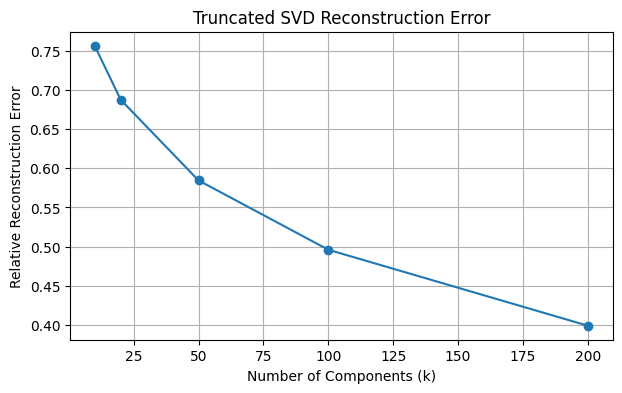

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(
    results_df["k"],
    results_df["Relative Reconstruction Error"],
    marker="o"
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")
plt.title("Truncated SVD Reconstruction Error")
plt.grid(True)
plt.show()

### Choice of k

Reconstruction error improves as k increases, but the gains become smaller at higher values. **k = 100** was chosen as a good balance between accuracy, speed, and model size.